# 🦠 Reworked COVID-19 Mortality Surge Benchmark (Weekly, Onset-Aligned)

### Data Sources
- **Regional All-Cause Mortality & 2015–2018 Historical Baselines:** [Eurostat (`demo_r_mwk3_ts`)](https://ec.europa.eu/eurostat/databrowser/view/demo_r_mwk3_ts/default/table?lang=en)
- **NUTS-3 Region Coordinates & Urban/Coast/Mountain Codes:** [Eurostat GISCO (`NUTS 2021` centroids)](https://ec.europa.eu/eurostat/web/gisco/geodata/statistical-units/territorial-units-statistics)
- **National COVID-19 Cases, Deaths & Policy Indices (NPIs):** [Oxford COVID-19 Government Response Tracker (`OxCGRT`)](https://github.com/OxCGRT/covid-policy-tracker)
- **National Population Denominators:** [Our World in Data (`OWID`)](https://github.com/owid/covid-19-data)

### Benchmark Design Highlights
1. **Exogenous Onset ($\tau = 0$):** Defined strictly from national `OxCGRT` confirmed COVID-19 mortality crossing `>= 1.5` then `>= 2.0` weekly deaths per 100k (stepped back to `>= 0.4` per 100k), never from the regional mortality peak.
2. **Clean Pre-Onset Baseline ($\tau < 0$):** 24 pre-onset weeks with normal pre-COVID mortality (no week > 1.40x pre-onset median) followed by a sustained multi-week surge (`>= 1.35x` post-onset).
3. **Pure Epidemiology & Seasonality (`past_future` without weather noise):** Uses each region's pre-COVID **2015–2018 expected weekly deaths**, dimensionless **seasonal baseline index**, astronomical **daylight hours**, and **ISO week of year** — zero weather forecasts or extraneous meteorological noise.
4. **Chronological & Disjoint Split:**
   - **Train (`N = 305` regions, 9 countries):** Spring 2020 wave (`onset <= 2020-W15`, windows end `<= 2020-W29`).
   - **Test (`N = 190` regions, 12 countries):** Fall 2020 wave (`2020-W38 <= onset <= 2020-W50`, zero country/region overlap, >= 9-week chronological gap).

### 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

### 2. Load Full Dataset, Summary & Feature Inventory

In [2]:
npz_path = 'data/reworked_covid_mortality_weekly.npz'
meta_path = 'data/reworked_covid_mortality_metadata.csv'

data = np.load(npz_path, allow_pickle=True)
meta = pd.read_csv(meta_path)

past_names = [str(x) for x in data['past_feature_names']]
pf_names = [str(x) for x in data['past_future_feature_names']]
static_names = [str(x) for x in data['static_feature_names']]
tau_steps = data['tau_steps']
week_strings = data['week_strings']

print(f'Samples (N):           {len(meta)}')
print(f'Weeks per sample (T):  {len(tau_steps)} (tau from {tau_steps[0]} to {tau_steps[-1]} weeks)')
print(f'Past covariates:       {len(past_names)} -> {past_names}')
print(f'Past-future covs:      {len(pf_names)} -> {pf_names}')
print(f'Static features:       {len(static_names)} -> {static_names}')

X_past = data['past_covariates']
X_pf = data['past_future_covariates']
X_static = data['static_features']
N, T, _ = X_past.shape

full_dict = {
    'sample_id': np.repeat(meta['sample_id'].values, T),
    'region_id': np.repeat(meta['region_id'].values, T),
    'region_name': np.repeat(meta['region_name'].values, T),
    'country_code': np.repeat(meta['country_code'].values, T),
    'split': np.repeat(meta['split'].values, T),
    'onset_week': np.repeat(meta['onset_week'].values, T),
    'iso_week': week_strings.reshape(-1),
    'tau_week': np.tile(tau_steps, N),
}
for i, col in enumerate(static_names):
    vals = np.repeat(X_static[:, i], T)
    full_dict[col] = vals.astype(int) if col in ('urban_type', 'coast_type', 'mount_type') else vals
for i, col in enumerate(past_names):
    full_dict[col] = X_past[:, :, i].reshape(-1)
for i, col in enumerate(pf_names):
    full_dict[col] = X_pf[:, :, i].reshape(-1)

full_df = pd.DataFrame(full_dict)
print(f'\nFlattened full table shape: {full_df.shape}')
display(meta.head())
display(full_df[past_names + pf_names].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Samples (N):           495
Weeks per sample (T):  41 (tau from -24 to 16 weeks)
Past covariates:       10 -> ['deaths_total', 'deaths_male', 'deaths_female', 'deaths_change_1w', 'deaths_rolling_mean_4w', 'covid_cases_100k', 'covid_deaths_100k', 'stringency_index', 'containment_index', 'gov_response_index']
Past-future covs:      5 -> ['hist_expected_deaths', 'hist_seasonal_index', 'daylight_hours', 'week_of_year', 'month']
Static features:       6 -> ['latitude', 'longitude', 'urban_type', 'coast_type', 'mount_type', 'hist_mean_weekly_deaths']

Flattened full table shape: (20295, 29)


,sample_id,region_id,region_name,country_code,iso3,split,onset_week,onset_date,window_start_week,window_end_week,baseline_median_deaths,hist_mean_weekly_deaths,pre_max_deaths,post_peak_deaths,post_peak_tau_week,post_peak_ratio,latitude,longitude,urban_type,coast_type,mount_type
0,0,ITC11,Torino,IT,ITA,train,2020-W10,2020-03-02,2019-W38,2020-W26,510.0,498.74,584.0,1044.0,3,2.047,45.1411,7.4470,1,3,2
1,1,ITC12,Vercelli,IT,ITA,train,2020-W10,2020-03-02,2019-W38,2020-W26,43.0,47.63,56.0,128.0,4,2.977,45.3119,8.2059,2,3,4
2,2,ITC13,Biella,IT,ITA,train,2020-W10,2020-03-02,2019-W38,2020-W26,46.5,48.43,61.0,120.0,5,2.581,45.5857,8.0828,2,3,3
3,3,ITC14,Verbano-Cusio-Ossola,IT,ITA,train,2020-W10,2020-03-02,2019-W38,2020-W26,39.0,39.33,50.0,86.0,3,2.205,46.0782,8.3494,2,3,3
4,4,ITC15,Novara,IT,ITA,train,2020-W10,2020-03-02,2019-W38,2020-W26,84.0,80.49,101.0,217.0,3,2.583,45.5598,8.5688,2,3,4


,count,mean,std,min,50%,max
deaths_total,20295.0,117.93,131.19,6.00,90.00,5342.00
deaths_male,20295.0,59.19,65.93,2.00,45.00,2912.00
deaths_female,20295.0,58.74,66.10,0.00,45.00,2742.00
deaths_change_1w,20295.0,0.37,38.77,-1524.00,0.00,2272.00
deaths_rolling_mean_4w,20295.0,117.38,125.98,9.75,90.00,4369.50
covid_cases_100k,20295.0,48.13,112.61,0.00,5.85,864.15
covid_deaths_100k,20295.0,1.76,3.06,0.00,0.18,18.47
stringency_index,20295.0,42.04,32.09,0.00,49.07,93.52
containment_index,20295.0,39.32,28.35,0.00,47.02,85.60
gov_response_index,20295.0,39.97,28.92,0.00,50.82,87.40


### 3. Derived Feature Evaluation & Correlation Matrix (Justifying Redundancy Removal)

Highly correlated feature pairs (|r| > 0.90):
  - deaths_total             vs deaths_male             : r = +0.994
  - deaths_total             vs deaths_female           : r = +0.994
  - deaths_total             vs deaths_rolling_mean_4w  : r = +0.942
  - deaths_male              vs deaths_female           : r = +0.975
  - deaths_male              vs deaths_rolling_mean_4w  : r = +0.921
  - deaths_female            vs deaths_rolling_mean_4w  : r = +0.951
  - stringency_index         vs containment_index       : r = +0.982
  - stringency_index         vs gov_response_index      : r = +0.977
  - containment_index        vs gov_response_index      : r = +0.996
  - week_of_year             vs month                   : r = +0.922

Low-correlation derived features vs primary target (deaths_total):
  - deaths_change_1w         vs deaths_total: r = +0.155
  - male_death_share         vs deaths_total: r = -0.008


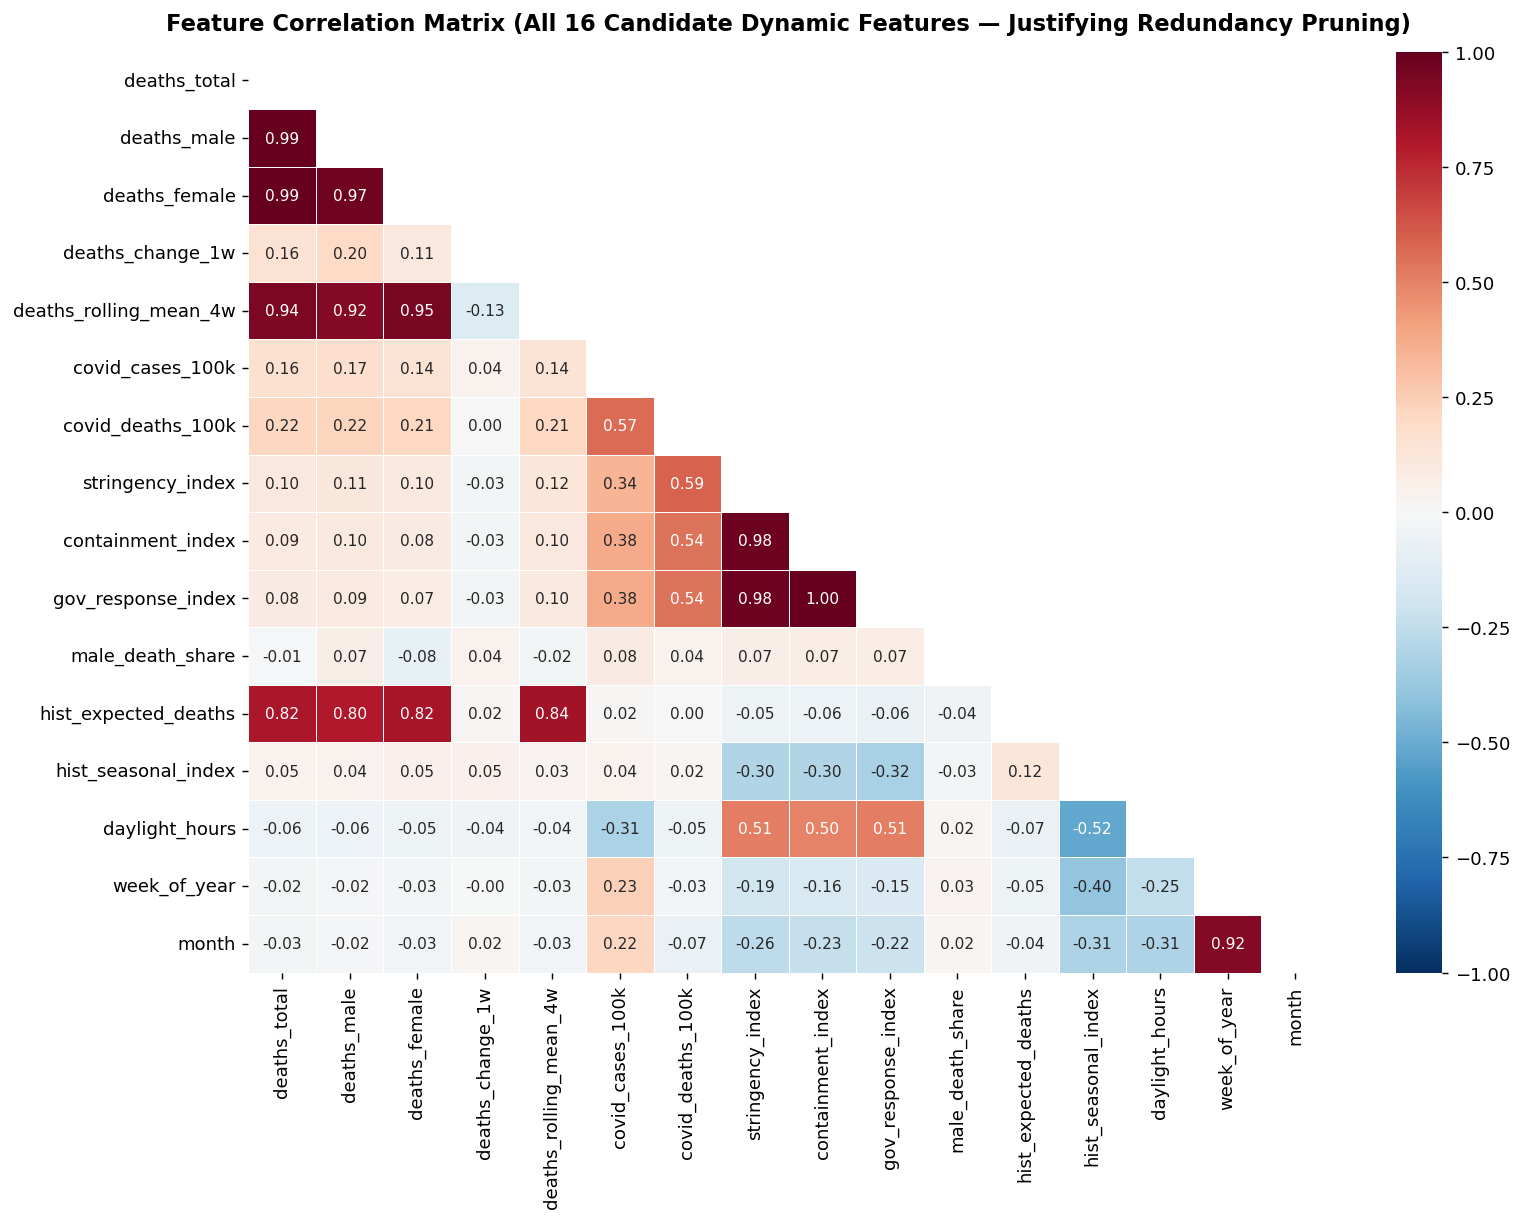

In [3]:
# Engineer demographic sex-skew covariate: male proportion of weekly deaths
# Scale-invariant and captures COVID-19 male excess risk without repeating deaths_total magnitude
full_df['male_death_share'] = full_df['deaths_male'] / full_df['deaths_total']

all_candidate_features = past_names + ['male_death_share'] + pf_names
corr = full_df[all_candidate_features].corr()

print('Highly correlated feature pairs (|r| > 0.90):')
for i in range(len(all_candidate_features)):
    for j in range(i + 1, len(all_candidate_features)):
        val = corr.iloc[i, j]
        if abs(val) > 0.90:
            print(f'  - {all_candidate_features[i]:24s} vs {all_candidate_features[j]:24s}: r = {val:+.3f}')

print('\nLow-correlation derived features vs primary target (deaths_total):')
for dcol in ['deaths_change_1w', 'male_death_share']:
    print(f'  - {dcol:24s} vs deaths_total: r = {corr.loc[dcol, "deaths_total"]:+.3f}')

fig, ax = plt.subplots(figsize=(12.5, 9.5), dpi=130)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 8.5},
    ax=ax,
)
ax.set_title(
    'Feature Correlation Matrix (All 16 Candidate Dynamic Features — Justifying Redundancy Pruning)',
    fontsize=12.5,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.savefig('data/covid_mortality_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Create Clean Non-Redundant Simple Dataset (`data/covid_mortality_simple.csv`)

In [4]:
# Drop the 6 redundant features where |r| > 0.90 against a more fundamental covariate:
#   - deaths_male (r=+0.994 vs deaths_total) & deaths_female (r=+0.994 vs deaths_total) -> keep deaths_total + male_death_share
#   - deaths_rolling_mean_4w (r=+0.942 vs deaths_total) -> smoothed lag of deaths_total
#   - containment_index (r=+0.982 vs stringency_index) & gov_response_index (r=+0.977 vs stringency_index)
#   - month (r=+0.922 vs week_of_year) -> coarser calendar grouping of ISO week_of_year
REDUNDANT_TO_DROP = [
    'deaths_male',
    'deaths_female',
    'deaths_rolling_mean_4w',
    'containment_index',
    'gov_response_index',
    'month',
]

KEEP_META = ['sample_id', 'region_id', 'region_name', 'country_code', 'split', 'onset_week', 'iso_week', 'tau_week']
KEEP_STATIC = static_names
KEEP_PAST = [c for c in past_names + ['male_death_share'] if c not in REDUNDANT_TO_DROP]
KEEP_PF = [c for c in pf_names if c not in REDUNDANT_TO_DROP]

simple_df = full_df[KEEP_META + KEEP_STATIC + KEEP_PAST + KEEP_PF].copy()
simple_df['week_of_year'] = simple_df['week_of_year'].astype(int)

kept_dyn = KEEP_PAST + KEEP_PF
kept_corr = simple_df[kept_dyn].corr().copy()
np.fill_diagonal(kept_corr.values, 0.0)
max_r = float(kept_corr.abs().max().max())

# Compute Variance Inflation Factors (VIF) across all kept dynamic columns
X_std = (simple_df[kept_dyn] - simple_df[kept_dyn].mean()) / simple_df[kept_dyn].std()
vifs = dict(zip(kept_dyn, np.diag(np.linalg.inv(np.corrcoef(X_std.values, rowvar=False)))))

print(f'Dropped {len(REDUNDANT_TO_DROP)} redundant features: {REDUNDANT_TO_DROP}')
print(f'Max off-diagonal |r| among {len(kept_dyn)} kept dynamic features: {max_r:.3f}')
print(f'Max VIF across kept dynamic features: {max(vifs.values()):.2f} ({max(vifs, key=vifs.get)})')
assert simple_df.isna().sum().sum() == 0, 'Unexpected NaNs found!'

simple_csv_path = 'data/covid_mortality_simple.csv'
simple_df.to_csv(simple_csv_path, index=False)
print(f'Saved: {simple_csv_path} ({os.path.getsize(simple_csv_path) / (1024**2):.2f} MB), shape={simple_df.shape}')
display(simple_df.head())

Dropped 6 redundant features: ['deaths_male', 'deaths_female', 'deaths_rolling_mean_4w', 'containment_index', 'gov_response_index', 'month']
Max off-diagonal |r| among 10 kept dynamic features: 0.818
Max VIF across kept dynamic features: 3.85 (deaths_total)


Saved: data/covid_mortality_simple.csv (3.11 MB), shape=(20295, 24)


,sample_id,region_id,region_name,country_code,split,onset_week,iso_week,tau_week,latitude,longitude,urban_type,coast_type,mount_type,hist_mean_weekly_deaths,deaths_total,deaths_change_1w,covid_cases_100k,covid_deaths_100k,stringency_index,male_death_share,hist_expected_deaths,hist_seasonal_index,daylight_hours,week_of_year
0,0,ITC11,Torino,IT,train,2020-W10,2019-W38,-24,45.141102,7.44703,1,3,2,498.736847,453.0,-3.0,0.0,0.0,0.0,0.507726,446.75,0.895763,12.027033,38
1,0,ITC11,Torino,IT,train,2020-W10,2019-W39,-23,45.141102,7.44703,1,3,2,498.736847,418.0,-35.0,0.0,0.0,0.0,0.509569,462.50,0.927343,11.648937,39
2,0,ITC11,Torino,IT,train,2020-W10,2019-W40,-22,45.141102,7.44703,1,3,2,498.736847,441.0,23.0,0.0,0.0,0.0,0.451247,449.25,0.900776,11.273421,40
3,0,ITC11,Torino,IT,train,2020-W10,2019-W41,-21,45.141102,7.44703,1,3,2,498.736847,478.0,37.0,0.0,0.0,0.0,0.476987,504.00,1.010553,10.903460,41
4,0,ITC11,Torino,IT,train,2020-W10,2019-W42,-20,45.141102,7.44703,1,3,2,498.736847,534.0,56.0,0.0,0.0,0.0,0.468165,477.00,0.956416,10.542439,42


### 5. Feature Inventory: Past-Only vs. Past-Future vs. Static

In [5]:
DESC = {
    'sample_id': 'Integer window ID (0..494)',
    'region_id': 'Eurostat NUTS-3 region code',
    'region_name': 'NUTS-3 region name',
    'country_code': '2-letter European country code',
    'split': 'Chronological split (train / test)',
    'onset_week': 'Exogenous national COVID wave onset week (tau=0)',
    'iso_week': 'Calendar ISO week string (YYYY-Www)',
    'tau_week': 'Weeks relative to wave onset (-24 to +16)',
    'latitude': 'Region centroid latitude (deg N)',
    'longitude': 'Region centroid longitude (deg E)',
    'urban_type': 'Eurostat typology (1=Urban, 2=Intermediate, 3=Rural)',
    'coast_type': 'Eurostat coast typology (1=Coastal, 2=Semi-coastal, 3=Inland)',
    'mount_type': 'Eurostat mountain typology (1..3=Mountainous, 4=Non-mountainous)',
    'hist_mean_weekly_deaths': 'Pre-COVID 2015-2018 overall mean weekly deaths (static scale)',
    'deaths_total': '[TARGET] Weekly all-cause deaths (Eurostat counts/week)',
    'deaths_change_1w': '1-week mortality change (deaths[t] - deaths[t-1])',
    'male_death_share': 'Male fraction of weekly deaths (deaths_male / deaths_total)',
    'covid_cases_100k': 'National weekly confirmed COVID cases per 100k (OxCGRT/OWID)',
    'covid_deaths_100k': 'National weekly confirmed COVID deaths per 100k (OxCGRT/OWID)',
    'stringency_index': 'OxCGRT Stringency Index (0-100 containment strictness)',
    'hist_expected_deaths': 'Pre-COVID 2015-2018 mean weekly deaths for same (region, week_of_year)',
    'hist_seasonal_index': 'Dimensionless 2015-2018 seasonal mortality index (expected / static mean)',
    'daylight_hours': 'Solar photoperiod at region latitude (hours/day)',
    'week_of_year': 'ISO calendar week of year (1-53)',
}

rows = []
for c in KEEP_META:
    rows.append({'column': c, 'role': 'METADATA', 'description': DESC[c]})
for c in KEEP_STATIC:
    rows.append({'column': c, 'role': 'STATIC', 'description': DESC[c]})
for c in KEEP_PAST:
    role = 'PAST_ONLY (TARGET)' if c == 'deaths_total' else 'PAST_ONLY'
    rows.append({'column': c, 'role': role, 'description': DESC[c]})
for c in KEEP_PF:
    rows.append({'column': c, 'role': 'PAST_FUTURE', 'description': DESC[c]})

display(pd.DataFrame(rows))

,column,role,description
0,sample_id,METADATA,Integer window ID (0..494)
1,region_id,METADATA,Eurostat NUTS-3 region code
2,region_name,METADATA,NUTS-3 region name
3,country_code,METADATA,2-letter European country code
4,split,METADATA,Chronological split (train / test)
5,onset_week,METADATA,Exogenous national COVID wave onset week (tau=0)
6,iso_week,METADATA,Calendar ISO week string (YYYY-Www)
7,tau_week,METADATA,Weeks relative to wave onset (-24 to +16)
8,latitude,STATIC,Region centroid latitude (deg N)
9,longitude,STATIC,Region centroid longitude (deg E)


### 6. Chronological Train / Test Split Summary

In [6]:
split_summary = meta.groupby('split').agg(
    num_regions=('sample_id', 'count'),
    num_countries=('country_code', 'nunique'),
    earliest_week=('window_start_week', 'min'),
    earliest_onset=('onset_week', 'min'),
    latest_onset=('onset_week', 'max'),
    latest_week=('window_end_week', 'max'),
    median_baseline_deaths=('baseline_median_deaths', 'median'),
    median_peak_deaths=('post_peak_deaths', 'median'),
    median_peak_ratio=('post_peak_ratio', 'median'),
)
display(split_summary)

print('Train countries:', {str(k): int(v) for k, v in meta[meta['split'] == 'train']['country_code'].value_counts().items()})
print('Test countries: ', {str(k): int(v) for k, v in meta[meta['split'] == 'test']['country_code'].value_counts().items()})

train_end = meta.loc[meta['split'] == 'train', 'window_end_week'].max()
test_onset = meta.loc[meta['split'] == 'test', 'onset_week'].min()
print(f'Chronological separation verified: latest train week ({train_end}) < earliest test onset ({test_onset})')

,num_regions,num_countries,earliest_week,earliest_onset,latest_onset,latest_week,median_baseline_deaths,median_peak_deaths,median_peak_ratio
split,,,,,,,,,
test,190,12,2020-W14,2020-W38,2020-W47,2021-W10,85.25,178.0,2.1245
train,305,9,2019-W38,2020-W10,2020-W13,2020-W29,77.50,167.0,1.9110


Train countries: {'UK': 90, 'IT': 66, 'FR': 40, 'ES': 32, 'NL': 27, 'BE': 23, 'SE': 13, 'CH': 10, 'PT': 4}
Test countries:  {'PL': 72, 'AT': 22, 'HU': 20, 'RS': 16, 'EL': 15, 'CZ': 14, 'SK': 8, 'LT': 8, 'LV': 6, 'DK': 6, 'EE': 2, 'CY': 1}
Chronological separation verified: latest train week (2020-W29) < earliest test onset (2020-W38)


### 7. Before & After Surge Visualization (1 Sample Region + All 495 Train vs. Test Regions)

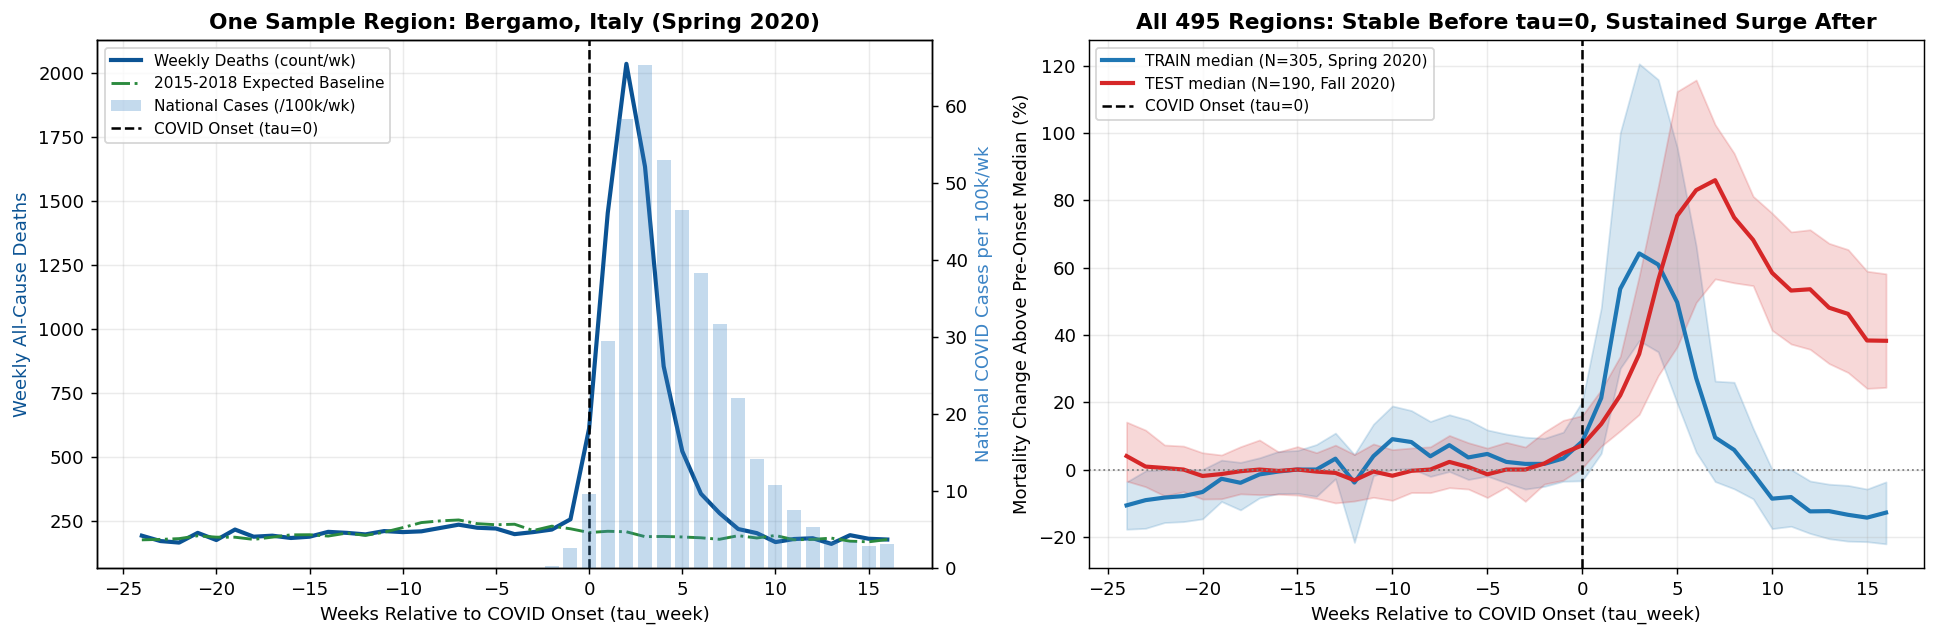

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130)

# --- Left Panel: One Sample Region (Bergamo, IT — Spring 2020) ---
ex = simple_df[simple_df['region_id'] == 'ITC46'].sort_values('tau_week')
ax1 = axes[0]
ax1_r = ax1.twinx()

l1, = ax1.plot(ex['tau_week'], ex['deaths_total'], color='#0b5394', lw=2.3, label='Weekly Deaths (count/wk)')
l_exp, = ax1.plot(ex['tau_week'], ex['hist_expected_deaths'], color='#2b8a3e', ls='-.', lw=1.6, label='2015-2018 Expected Baseline')
b1 = ax1_r.bar(ex['tau_week'], ex['covid_cases_100k'], width=0.75, color='#3d85c6', alpha=0.30, label='National Cases (/100k/wk)')
v1 = ax1.axvline(0, color='black', ls='--', lw=1.4, label='COVID Onset (tau=0)')

ax1.set_title('One Sample Region: Bergamo, Italy (Spring 2020)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Weeks Relative to COVID Onset (tau_week)')
ax1.set_ylabel('Weekly All-Cause Deaths', color='#0b5394')
ax1_r.set_ylabel('National COVID Cases per 100k/wk', color='#3d85c6')
ax1.grid(True, alpha=0.25)
ax1.legend([l1, l_exp, b1, v1], [l1.get_label(), l_exp.get_label(), b1.get_label(), v1.get_label()], loc='upper left', fontsize=8.5)

# --- Right Panel: All 495 Regions — Excess Mortality % Above Pre-Onset Median ---
pre_med = simple_df[simple_df['tau_week'] < 0].groupby('sample_id')['deaths_total'].median().rename('pre_med')
df_rel = simple_df.merge(pre_med, on='sample_id')
df_rel['pct_above_baseline'] = (df_rel['deaths_total'] / df_rel['pre_med'] - 1.0) * 100.0

ax2 = axes[1]
for split_name, color, label in [('train', '#1f77b4', 'TRAIN median (N=305, Spring 2020)'),
                                 ('test', '#d62728', 'TEST median (N=190, Fall 2020)')]:
    sub = df_rel[df_rel['split'] == split_name]
    stats = sub.groupby('tau_week')['pct_above_baseline'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax2.plot(stats['tau_week'], stats['med'], color=color, lw=2.3, label=label)
    ax2.fill_between(stats['tau_week'], stats['q25'], stats['q75'], color=color, alpha=0.18)

ax2.axhline(0, color='gray', ls=':', lw=1.0)
ax2.axvline(0, color='black', ls='--', lw=1.4, label='COVID Onset (tau=0)')
ax2.set_title('All 495 Regions: Stable Before tau=0, Sustained Surge After', fontsize=12, fontweight='bold')
ax2.set_xlabel('Weeks Relative to COVID Onset (tau_week)')
ax2.set_ylabel('Mortality Change Above Pre-Onset Median (%)')
ax2.grid(True, alpha=0.25)
ax2.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig('data/covid_mortality_simple_overview.png', dpi=150, bbox_inches='tight')
plt.show()